In [3]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from herbie import FastHerbie, Herbie, HerbieLatest
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import xarray as xr

In [4]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = HerbieLatest(
    model="hrrr",
    product="sfc",
    fxx=6,
)
t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
               )
# # Create a DataArray with initial coordinates
# t2m = xr.DataArray(
#     t2m_ds['t2m'].values,
#     coords={
#         'lon': ('lon', t2m_ds.longitude.values[:,0]),  # Assign longitude coordinate
#         'lat': ('lat', t2m_ds.latitude.values[:,0])  # Assign latitude coordinate
#     },
#     dims=['lon', 'lat']  # Define dimensions
# )


t2m_ds

💔 Did not find ┊ model=hrrr ┊ product=sfc ┊ 2024-Nov-19 17:00 UTC F06
💔 Did not find ┊ model=hrrr ┊ product=sfc ┊ 2024-Nov-19 16:00 UTC F06
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Nov-19 15:00 UTC F06 ┊ GRIB2 @ aws ┊ IDX @ aws
👨🏻‍🏭 Created directory: [/Users/jglarson/data/hrrr/20241119]


/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/xarray/backends/plugins.py:75: RuntimeWarning: Engine 'gini' loading failed:
cannot inherit frozen dataclass from a non-frozen one
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


<xarray.Dataset> Size: 38MB
Dimensions:              (y: 1059, x: 1799)
Coordinates:
    time                 int64 8B 1732028400
    step                 float64 8B 6.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           float64 8B 1.732e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Data variables:
    t2m                  (y, x) float32 8MB 294.8 294.8 294.8 ... 278.0 278.0
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 sfc
    description:             High-Resolution Rapid Refresh - CONUS
    remote_grib:             https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr....
    local_grib:              /Users/jglarson/data/hrrr/20241119/subset_d9b2fd...
    search:                  TMP:2 m above

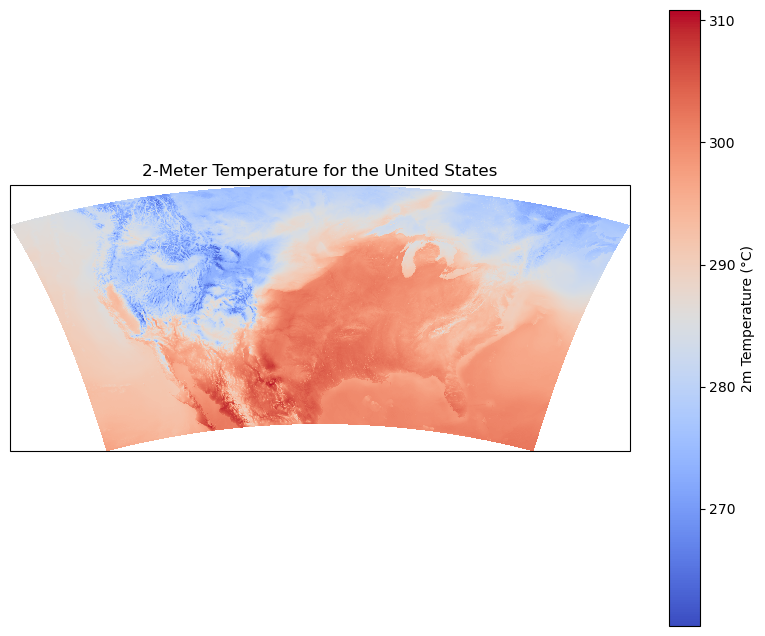

In [108]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

t2mColo = t2m_ds['t2m']#[200:1000, 200:900]


# Assuming 'temperature' is your DataArray with dimensions lat and lon
# Set up the figure and axis with Cartopy for a projection
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.AzimuthalEquidistant()})

# # Plot the data
# t2m.plot(ax=ax, cmap='coolwarm', cbar_kwargs={'label': '2m Temperature (°C)'})
# Manually plot with pcolormesh
plt.pcolormesh(t2mColo.longitude, t2mColo.latitude, t2mColo, cmap='coolwarm')
plt.colorbar(label="2m Temperature (°C)")


# Add coastlines, states, and a title
ax.coastlines()
ax.set_title("2-Meter Temperature for the United States")
ax.add_feature(cfeature.STATES, edgecolor='black')
plt.show()


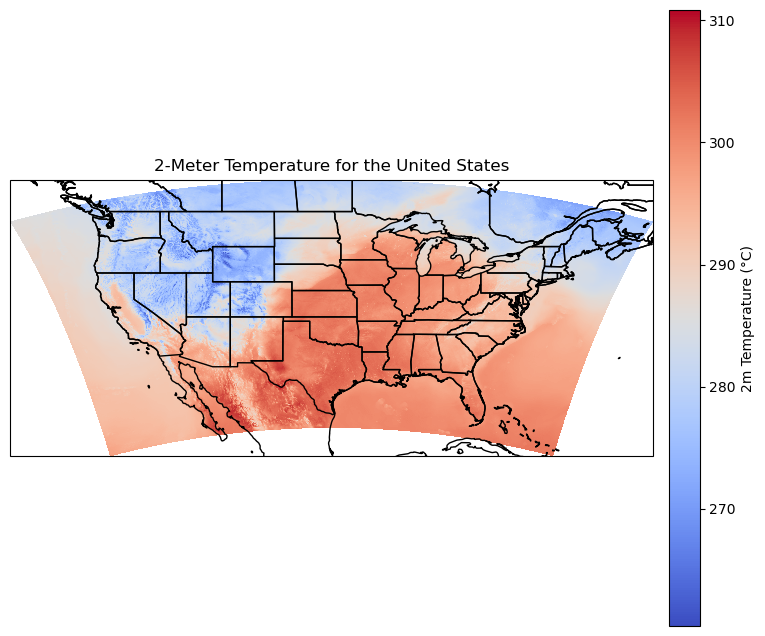

In [117]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Assuming t2m_ds['t2m'] is your DataArray
t2mColo = t2m_ds['t2m']  # Make sure this has the right dimensions

# Set up the figure and axis with Cartopy for a projection
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# Manually plot with ax.pcolormesh
# Note: Make sure to set the extent to cover the area of interest (e.g., the US)
pcm = ax.pcolormesh(t2mColo.longitude, t2mColo.latitude, t2mColo,
                     cmap='coolwarm', transform=ccrs.PlateCarree())

# Add colorbar with label
cbar = fig.colorbar(pcm, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("2m Temperature (°C)")

# Add coastlines and states
ax.coastlines()
ax.add_feature(cfeature.STATES, edgecolor='black')

# Set the title
ax.set_title("2-Meter Temperature for the United States")

# Set extent if necessary (optional)
# ax.set_extent([-130, -60, 25, 50], crs=ccrs.PlateCarree())

# Show the plot
plt.show()


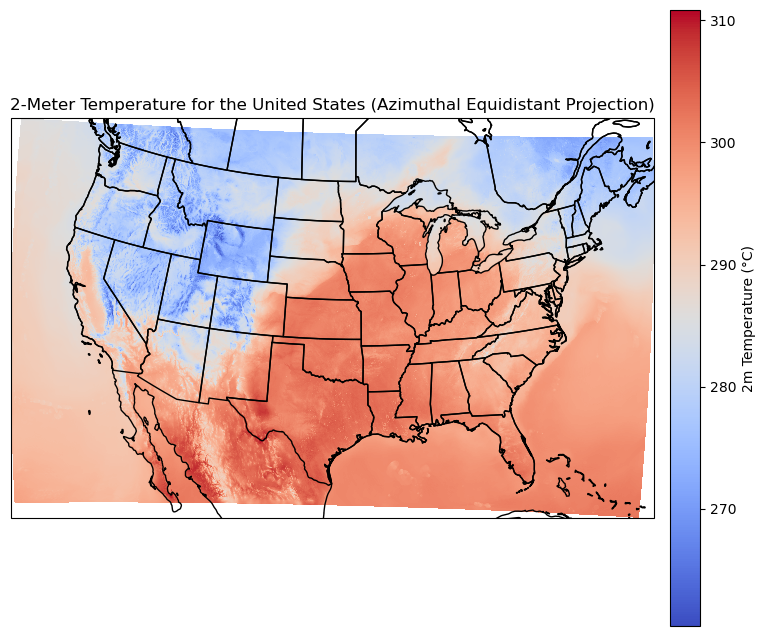

In [118]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Assuming t2m_ds['t2m'] is your DataArray
t2mColo = t2m_ds['t2m']  # Make sure this has the right dimensions

# Set the center of the projection (latitude, longitude)
projection_center = (37.5, -95.0)  # Center on the continental US

# Set up the figure and axis with Cartopy for the Azimuthal Equidistant projection
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.AzimuthalEquidistant(central_longitude=projection_center[1], central_latitude=projection_center[0])})

# Manually plot with ax.pcolormesh
# Use the PlateCarree transform for longitude and latitude
pcm = ax.pcolormesh(t2mColo.longitude, t2mColo.latitude, t2mColo, 
                     cmap='coolwarm', transform=ccrs.PlateCarree())

# Add colorbar with label
cbar = fig.colorbar(pcm, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("2m Temperature (°C)")

# Add coastlines and states
ax.coastlines()
ax.add_feature(cfeature.STATES, edgecolor='black')

# Set the title
ax.set_title("2-Meter Temperature for the United States (Azimuthal Equidistant Projection)")

# Show the plot
plt.show()


In [4]:
t2m_ds

<xarray.Dataset> Size: 38MB
Dimensions:              (y: 1059, x: 1799)
Coordinates:
    time                 int64 8B 1731963600
    step                 float64 8B 6.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           float64 8B 1.732e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Data variables:
    t2m                  (y, x) float32 8MB 294.7 294.7 294.7 ... 278.2 278.3
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 sfc
    description:             High-Resolution Rapid Refresh - CONUS
    remote_grib:             https://nomads.ncep.noaa.gov/pub/data/nccf/com/h...
    local_grib:              /Users/jglarson/data/hrrr/20241118/subset_84b2fd...
    search:                  TMP:2 m above

In [9]:
t2m_ds.latitude.values

array([[21.138123  , 21.14511004, 21.1520901 , ..., 21.1545089 ,
        21.14753125, 21.14054663],
       [21.16299459, 21.1699845 , 21.17696744, ..., 21.17938723,
        21.1724067 , 21.16541921],
       [21.18786863, 21.19486142, 21.20184723, ..., 21.20426802,
        21.19728462, 21.19029425],
       ...,
       [47.78955926, 47.799849  , 47.81012868, ..., 47.81369093,
        47.80341474, 47.79312849],
       [47.81409316, 47.82438621, 47.8346692 , ..., 47.83823259,
        47.8279531 , 47.81766354],
       [47.8386235 , 47.84891986, 47.85920615, ..., 47.86277069,
        47.85248789, 47.84219502]])

In [24]:
t2m_ds.x

<xarray.DataArray 'x' (x: 1799)> Size: 14kB
array([   0,    1,    2, ..., 1796, 1797, 1798])
Coordinates:
    time                 int64 8B 1731963600
    step                 float64 8B 6.0
    heightAboveGround    float64 8B 2.0
    valid_time           float64 8B 1.732e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: x

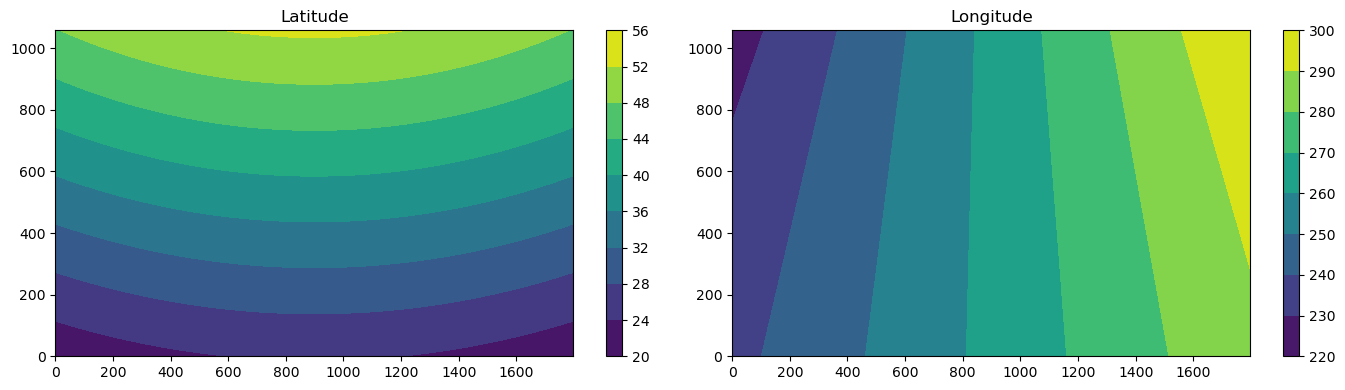

In [ ]:
# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4))

# First subplot - Latitude
im1 = ax1.contourf(t2m_ds.latitude)
ax1.set_title('Latitude')
plt.colorbar(im1, ax=ax1)

# Second subplot - Longitude 
im2 = ax2.contourf(t2m_ds.longitude)
ax2.set_title('Longitude')
plt.colorbar(im2, ax=ax2)

# Adjust layout to prevent overlap
plt.tight_layout()

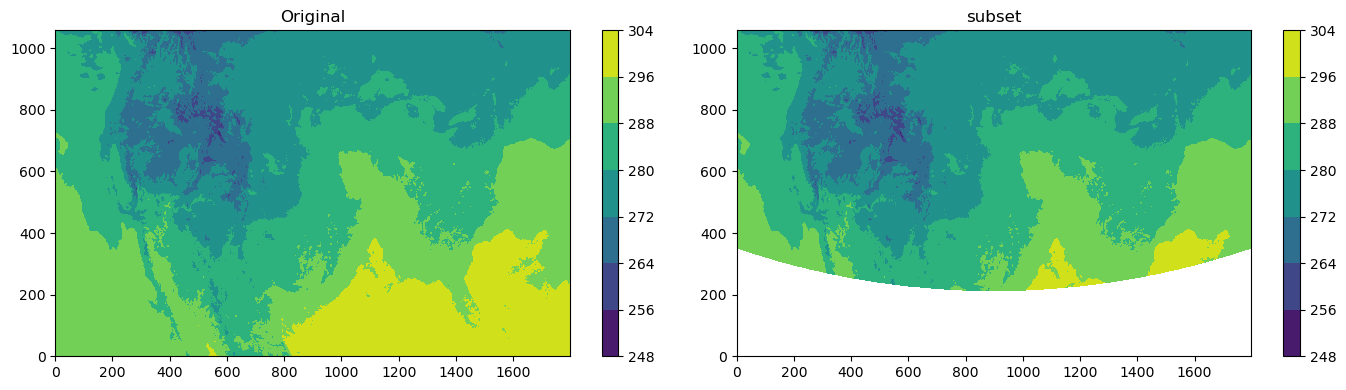

In [22]:

# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4))

# First subplot - Latitude
im1 = ax1.contourf(t2m_ds['t2m'].values)
ax1.set_title('Original')
plt.colorbar(im1, ax=ax1)

# Second subplot - Longitude 
im2 = ax2.contourf(t2m_ds['t2m'].where(t2m_ds['latitude'] > 30).values)
ax2.set_title('subset')
plt.colorbar(im2, ax=ax2)

# Adjust layout to prevent overlap
plt.tight_layout()

## To Do: Index search through latitude and longitude to find the appropriate values for a given lat lon pair

In [11]:
def sel_region(da, center, width): 
    half_width = width / 2
    da = da.where(da['latitude'] > center[0] - half_width, drop=True)
    da = da.where(da['latitude'] < center[0] + half_width, drop=True)
    da = da.where(da['longitude'] > center[1] - half_width, drop=True)
    return da.where(da['longitude'] < center[1] + half_width, drop=True)

In [14]:
sel_region(t2m_ds['t2m'], [39, 360-105.7], 7)

<xarray.DataArray 't2m' (y: 426, x: 235)> Size: 400kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)
Coordinates:
    time                 int64 8B 1732028400
    step                 float64 8B 6.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 801kB 34.9 34.9 34.9 ... 46.85 46.85
    longitude            (y, x) float64 801kB 250.8 250.8 250.9 ... 257.7 257.8
    valid_time           float64 8B 1.732e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Attributes: (12/38)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1905141
    GRIB_typeOfLevel:                         heightAboveGround
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_stepRange:                           6
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            air_temperature
    grid_mapping:                             gribfile_projection

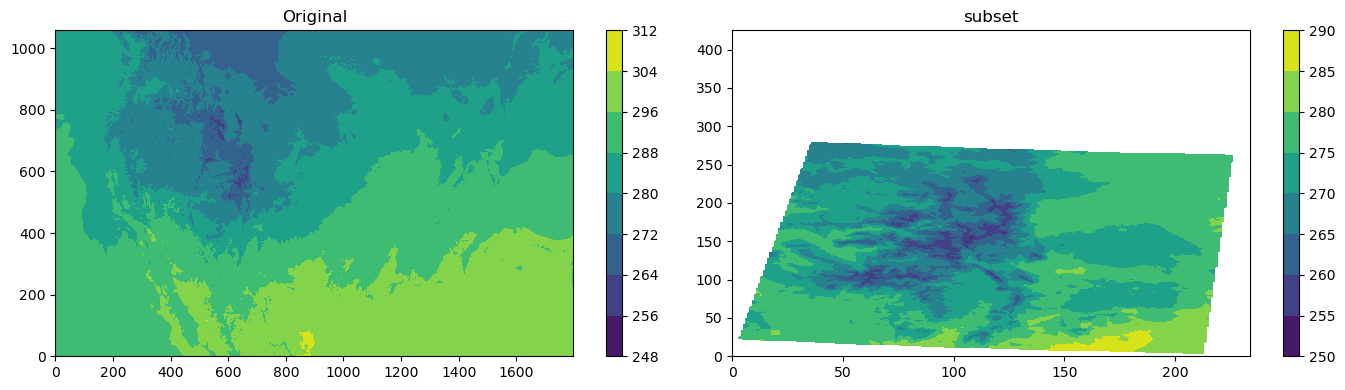

In [16]:

# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4))

# First subplot - Latitude
im1 = ax1.contourf(t2m_ds['t2m'])
ax1.set_title('Original')
plt.colorbar(im1, ax=ax1)

# Second subplot - Longitude 
im2 = ax2.contourf(sel_region(t2m_ds['t2m'], [39, 360-105.7], 7))
ax2.set_title('subset')
plt.colorbar(im2, ax=ax2)

# Adjust layout to prevent overlap
plt.tight_layout()

/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


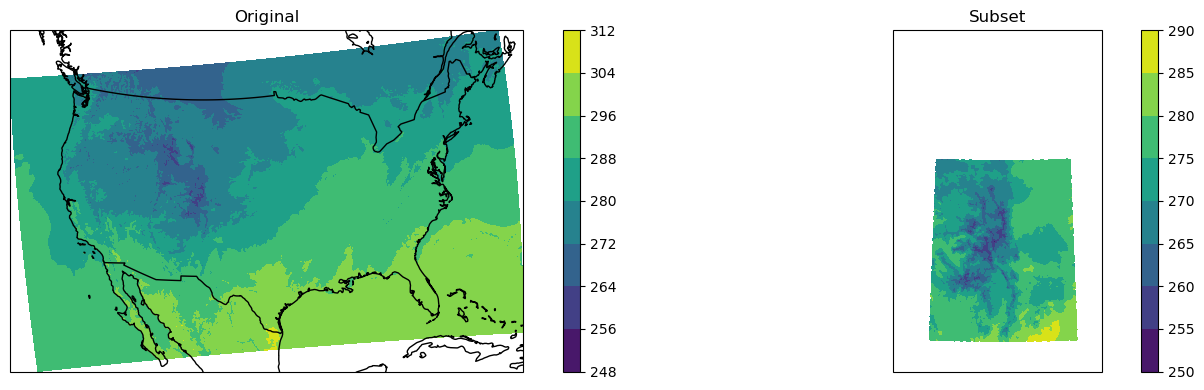

In [26]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create AzimuthalEquidistant projection
proj = ccrs.AzimuthalEquidistant(central_longitude=-105.7, central_latitude=39)

# Create figure and subplots with projection
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4),
                              subplot_kw={'projection': proj})

# First subplot - Original data
im1 = ax1.contourf(t2m_ds.longitude.values, t2m_ds.latitude.values, t2m_ds['t2m'].values,
                   transform=ccrs.PlateCarree())
ax1.set_title('Original')
ax1.coastlines()
ax1.add_feature(cfeature.BORDERS)
plt.colorbar(im1, ax=ax1)

# Second subplot - Subset data
subset = sel_region(t2m_ds['t2m'], [39, 360-105.7], 7)
im2 = ax2.contourf(subset.longitude.values, subset.latitude.values, subset.values,
                   transform=ccrs.PlateCarree())
ax2.set_title('Subset')
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS)
plt.colorbar(im2, ax=ax2)

plt.tight_layout()

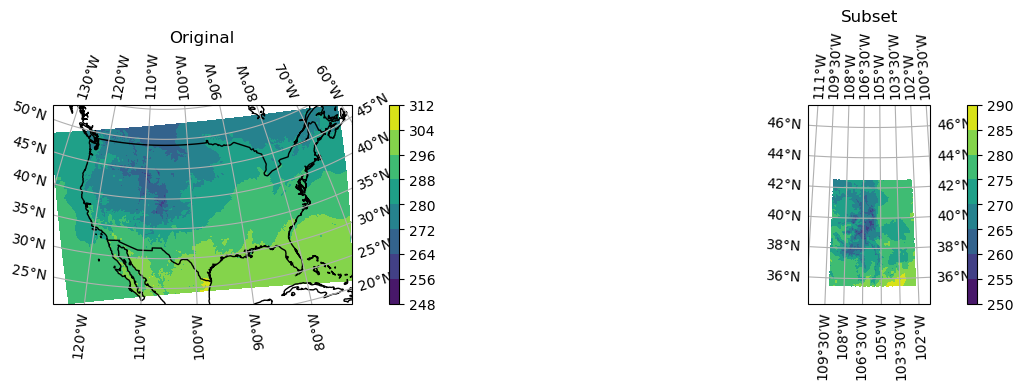

In [27]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create AzimuthalEquidistant projection
proj = ccrs.AzimuthalEquidistant(central_longitude=-105.7, central_latitude=39)

# Create figure and subplots with projection
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4),
                              subplot_kw={'projection': proj})

# First subplot - Original data
im1 = ax1.contourf(t2m_ds.longitude.values, t2m_ds.latitude.values, t2m_ds['t2m'].values,
                   transform=ccrs.PlateCarree())
ax1.set_title('Original')
ax1.coastlines()
ax1.add_feature(cfeature.BORDERS)
ax1.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im1, ax=ax1)

# Second subplot - Subset data
subset = sel_region(t2m_ds['t2m'], [39, 360-105.7], 7)
im2 = ax2.contourf(subset.longitude.values, subset.latitude.values, subset.values,
                   transform=ccrs.PlateCarree())
ax2.set_title('Subset')
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS)
ax2.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im2, ax=ax2)

plt.tight_layout()